# Exercice 19 — Pipeline complet de machine learning

In [259]:
import numpy as np

import pandas as pd

from scipy.special import expit

from scipy.optimize import brentq

import seaborn as sns

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split , cross_val_score , RandomizedSearchCV , StratifiedKFold

from sklearn.compose import ColumnTransformer

from sklearn.feature_selection import SelectKBest , f_classif 

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier

from sklearn.metrics import accuracy_score , precision_score , recall_score , f1_score , roc_auc_score 

from sklearn.impute import SimpleImputer , KNNImputer

from sklearn.preprocessing import StandardScaler , OneHotEncoder

from sklearn.pipeline import make_pipeline , Pipeline

### Generation du dataset

In [260]:
n= 2000

df =  pd.DataFrame({

    "anciennete_mois" : np.random.uniform(0,72, n).astype(int),

    "montant_mensuel" :  np.random.normal(65, 20, n).astype(int),

    "nb_reclamations" : np.random.poisson(1.2 , n),

    "type_contrat" :  np.random.choice(["Mensuel", "Annuel", "Biennal"], n),

    "methode_paiement" :  np.random.choice(["Carte", "Virement", "Prélèvement", "Chèque"], n),

    "service_internet" :  np.random.choice(["Fibre", "ADSL", "Aucun"],n)

})


df

,anciennete_mois,montant_mensuel,nb_reclamations,type_contrat,methode_paiement,service_internet
0,2,84,2,Biennal,Carte,ADSL
1,19,50,3,Mensuel,Chèque,Fibre
2,10,74,1,Biennal,Carte,Fibre
3,34,54,1,Mensuel,Prélèvement,Aucun
4,50,32,2,Annuel,Prélèvement,Aucun
...,...,...,...,...,...,...
1995,29,64,1,Mensuel,Chèque,ADSL
1996,35,58,1,Annuel,Carte,Aucun
1997,70,90,0,Biennal,Virement,Aucun
1998,43,58,3,Mensuel,Chèque,Fibre


### Fonction du calcul de "churn"

In [261]:
def cal_churn(df):

    rng = np.random.default_rng(42)

    anciennete = (

        df["anciennete_mois"] - df["anciennete_mois"].mean()

    ) / df["anciennete_mois"].std()

    reclamations = (

        df["nb_reclamations"] - df["nb_reclamations"].mean()

    ) / df["nb_reclamations"].std()

    def calcul_probabilite(intercept):

        return expit(

            intercept - 1.0 * anciennete + 1.2 * reclamations

        )

    intercept = brentq(

        lambda b: calcul_probabilite(b).mean() - 0.20,

        -20,

        20
    )

    probabilite = calcul_probabilite(intercept)

    df = df.copy()
    
    df["churn"] = rng.binomial(1, probabilite)

    return df

### Application de la fonction

In [262]:
df = cal_churn(df)

df

,anciennete_mois,montant_mensuel,nb_reclamations,type_contrat,methode_paiement,service_internet,churn
0,2,84,2,Biennal,Carte,ADSL,0
1,19,50,3,Mensuel,Chèque,Fibre,1
2,10,74,1,Biennal,Carte,Fibre,1
3,34,54,1,Mensuel,Prélèvement,Aucun,0
4,50,32,2,Annuel,Prélèvement,Aucun,0
...,...,...,...,...,...,...,...
1995,29,64,1,Mensuel,Chèque,ADSL,0
1996,35,58,1,Annuel,Carte,Aucun,0
1997,70,90,0,Biennal,Virement,Aucun,0
1998,43,58,3,Mensuel,Chèque,Fibre,1


### Injection des valeurs manquantes

In [263]:
df["anciennete_mois"] = df["anciennete_mois"].mask(

    np.random.random(len(df)) < 0.05

)

df["montant_mensuel"] = df["montant_mensuel"].mask(

    np.random.random(len(df)) < 0.03

)

df["type_contrat"] = df["type_contrat"].mask(

    np.random.random(len(df)) < 0.04

)

df.isna().sum()

y =  df["churn"]


### Construction d'un ColumnTransformer

In [264]:
num = ["anciennete_mois","montant_mensuel","nb_reclamations"]

cat = ["type_contrat","methode_paiement","service_internet"]

num_pipeline =  make_pipeline(

    KNNImputer(n_neighbors=20),
    
    StandardScaler() , 

)

cat_pipeline = make_pipeline(

    SimpleImputer(strategy="most_frequent"),

    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
    
)

prepro = ColumnTransformer(

    transformers=[

        ("Numerique" , num_pipeline , num),

        ("Categorie" , cat_pipeline , cat)
    ],
    verbose_feature_names_out=False
    
).set_output(transform="pandas")


### Ajoute de l'etape de de selection dans la pipeline

In [265]:
chaine =  make_pipeline(

    (prepro) ,

    (SelectKBest(score_func=f_classif,k=6).set_output(transform="pandas"))

)

df  =  chaine.fit_transform(df,y)


df

,anciennete_mois,montant_mensuel,nb_reclamations,type_contrat_Biennal,type_contrat_Mensuel,methode_paiement_Virement
0,-1.644622,0.996832,0.705672,1.0,0.0,0.0
1,-0.790768,-0.720886,1.609800,0.0,1.0,0.0
2,-1.242808,0.491621,-0.198456,1.0,0.0,0.0
3,-0.037367,-0.518801,-0.198456,0.0,1.0,0.0
4,0.766260,-1.630266,0.705672,0.0,0.0,0.0
...,...,...,...,...,...,...
1995,-0.288501,-0.013590,-0.198456,0.0,1.0,0.0
1996,0.012859,-0.316717,-0.198456,0.0,0.0,0.0
1997,1.770793,1.299959,-1.102584,1.0,0.0,1.0
1998,0.414673,-0.316717,1.609800,0.0,1.0,0.0


### Separation du train et du test 

In [266]:
X = df.copy()

x_train, x_test, y_train, y_test = train_test_split( X, y, test_size=0.2)

### Entrainement de 3 models

In [267]:
model1 =  LogisticRegression()

model2 =  RandomForestClassifier()

model3 = GradientBoostingClassifier()


models = {

    "LogisticRegression" : model1 ,

    "RandomForestClassifier" : model2 ,

    "GradientBoostingClassifier" : model3

}

cross_val = {
}

cv =  StratifiedKFold(n_splits=10)

for name , model in models.items() :

    

    cross_val[name]= cross_val_score(model,x_train, y_train,cv=cv ,  scoring="f1")


In [268]:
for name , score in cross_val.items():

    print (f"Model {name} : " ,score.mean())

Model LogisticRegression :  0.4572942559526538
Model RandomForestClassifier :  0.38595479538103045
Model GradientBoostingClassifier :  0.44999299815671057


### Rechecher d'hyper param sur "LogisticRegression"

In [269]:
model1.get_params().items()

dict_items([('C', 1.0), ('class_weight', None), ('dual', False), ('fit_intercept', True), ('intercept_scaling', 1), ('l1_ratio', 0.0), ('max_iter', 100), ('n_jobs', None), ('penalty', 'deprecated'), ('random_state', None), ('solver', 'lbfgs'), ('tol', 0.0001), ('verbose', 0), ('warm_start', False)])

In [270]:
param_grid = {

    "C": [0.001, 0.01, 0.1, 1, 10, 100],

    "solver": ["lbfgs", "liblinear", "saga"],

    "class_weight": [None, "balanced"],

    "fit_intercept": [True, False],

    "tol": [1e-3, 1e-4, 1e-5],

    "max_iter": [500, 1000, 2000]

}

chercher = RandomizedSearchCV(

    estimator=model1 ,

    param_distributions = param_grid, 

    cv = cv ,

    n_jobs=-1 

)

chercher.fit(x_train,y_train)


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'C': [0.001, 0.01, ...], 'class_weight': [None, 'balanced'], 'fit_intercept': [True, False], 'max_iter': [500, 1000, ...], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo...shuffle=False)
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto

In [271]:
chercher.best_params_

{'tol': 0.0001,
 'solver': 'saga',
 'max_iter': 2000,
 'fit_intercept': True,
 'class_weight': None,
 'C': 1}

### Utilisation des best params

In [272]:
model1 =  LogisticRegression(chercher.best_params_)

### Évalue le pipeline optimisé sur le jeu de test mis de côté à l'étape 1 (accuracy, précision, rappel, F1, AUC-ROC)

In [280]:
metric =  {}

for name , model in models.items():

    model.fit(x_train, y_train)

    model.score(x_train, y_train)

    pred = model.predict(x_test)

    metric[name] = {

        "accuracy": accuracy_score(y_test, pred),

        "precision": precision_score(y_test, pred),

        "recall": recall_score(y_test, pred),

        "f1_score": f1_score(y_test, pred),

        "auc_roc"  : roc_auc_score(y_test, pred),

    }

### Construis avec Pandas un tableau de synthèse regroupant

In [281]:
metric  = pd.DataFrame(metric)

metric


,LogisticRegression,RandomForestClassifier,GradientBoostingClassifier
accuracy,0.850000,0.827500,0.847500
precision,0.729730,0.580000,0.690476
recall,0.350649,0.376623,0.376623
f1_score,0.473684,0.456693,0.487395
auc_roc,0.659845,0.655804,0.668188


### Visualisation de ce tableau

<Axes: >

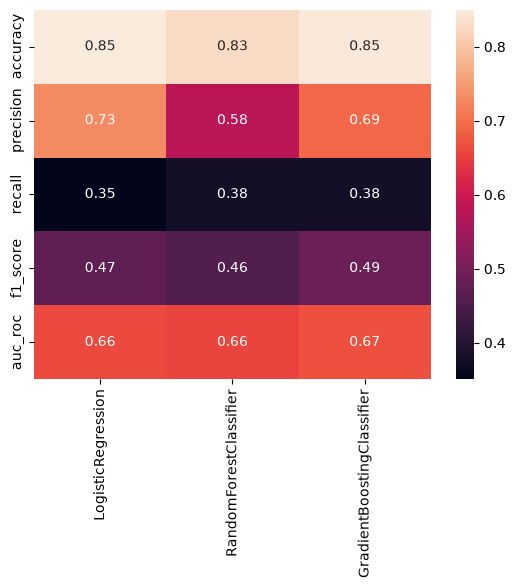

In [282]:
fig , ax =  plt.subplots()


sns.heatmap(

    metric ,

    annot=True,


)
